# Homework 5

Name: Xiaoyi Kuang  
GitHub username: Xiaoyi-Kuang1

## 1. 

### (a)

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import KFold, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

pd.set_option('display.max_rows', 150)
pd.set_option('display.max_colwidth', 60)
places = [Path('data'), Path('../data'), Path('../../data')]
folder = None
for place in places:
    if (place / 'communities.data').exists():
        folder = place
        break
if folder is None:
    raise FileNotFoundError('Put the data folder next to this notebook.')


In [2]:
column_names = ['temperature', 'nausea', 'lumbar_pain', 'urine_pushing', 'urination_pain', 'burning', 'bladder', 'nephritis']
data = pd.read_csv(folder / 'diagnosis.data', sep='\t', encoding='utf-16', decimal=',', header=None, names=column_names)
data = data.replace({'yes': 1, 'no': 0})
x = data.iloc[:, :6]
y = data['bladder'].astype(str) + data['nephritis'].astype(str)
print('Data shape:', data.shape)
display(data.head())

Data shape: (120, 8)


,temperature,nausea,lumbar_pain,urine_pushing,urination_pain,burning,bladder,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b)

The data has two labels: bladder and nephritis. I use the label powerset method. I join the two labels into one label with four classes (00, 01, 10 and 11, in the order bladder and nephritis). 

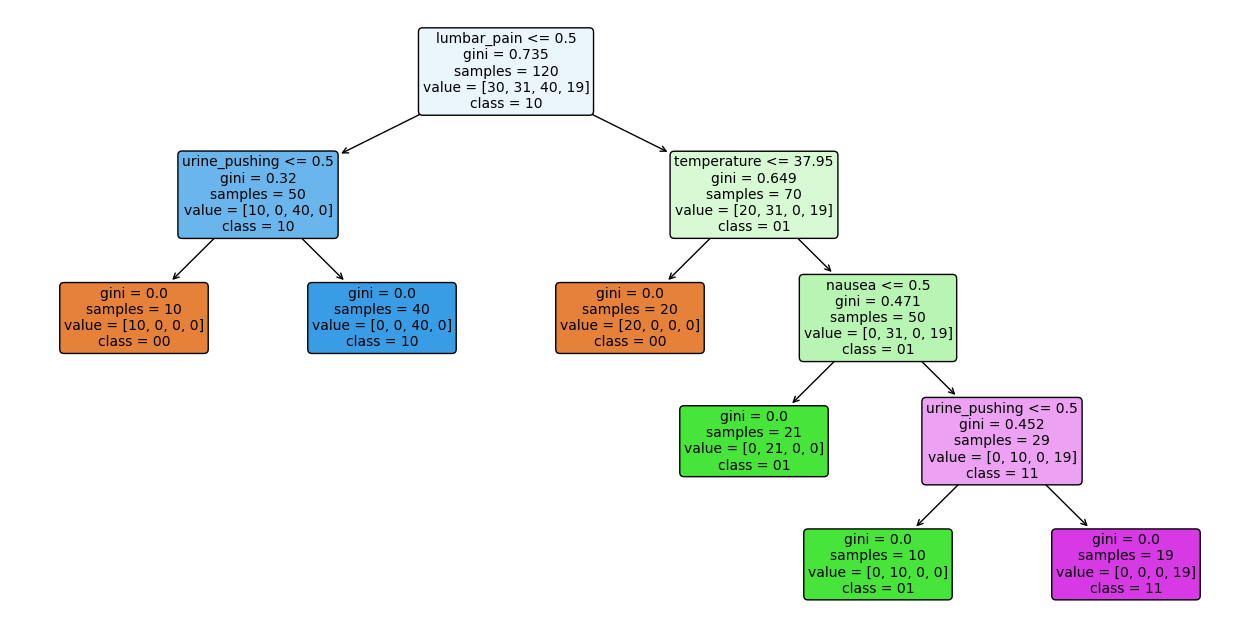

In [3]:
tree = DecisionTreeClassifier(random_state=1)
tree.fit(x, y)
plt.figure(figsize=(16, 8))
plot_tree(tree, feature_names=list(x.columns), class_names=list(tree.classes_), filled=True, rounded=True, fontsize=10)
plt.show()

### (c)

1. IF lumbar pain = no AND urine pushing = no, THEN bladder = no, nephritis = no.
2. IF lumbar pain = no AND urine pushing = yes, THEN bladder = yes, nephritis = no.
3. IF lumbar pain = yes AND temperature <= 37.95, THEN bladder = no, nephritis = no.
4. IF lumbar pain = yes AND temperature > 37.95 AND nausea = no, THEN bladder = no, nephritis = yes.
5. IF lumbar pain = yes AND temperature > 37.95 AND nausea = yes AND urine pushing = no, THEN bladder = no, nephritis = yes.
6. IF lumbar pain = yes AND temperature > 37.95 AND nausea = yes AND urine pushing = yes, THEN bladder = yes, nephritis = yes.

### (d)

In [4]:
prune_path = tree.cost_complexity_pruning_path(x, y)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
rows = []
for a in prune_path.ccp_alphas:
    model = DecisionTreeClassifier(ccp_alpha=a, random_state=1)
    scores = cross_val_score(model, x, y, cv=folds, scoring='accuracy')
    model.fit(x, y)
    rows.append([a, model.get_n_leaves(), model.get_depth(), model.score(x, y), scores.mean()])

pruning = pd.DataFrame(rows, columns=['alpha', 'leaves', 'depth', 'train_accuracy', 'cv_accuracy'])
best_score = pruning['cv_accuracy'].max()
best_alpha = pruning.loc[pruning['cv_accuracy'] == best_score, 'alpha'].max()
small_tree = DecisionTreeClassifier(ccp_alpha=best_alpha, random_state=1)
small_tree.fit(x, y)
display(pruning)
print('Selected alpha:', best_alpha)

,alpha,leaves,depth,train_accuracy,cv_accuracy
0,0.000000,6,4,1.000000,0.975000
1,0.098167,4,2,0.841667,0.808333
2,0.133333,3,2,0.758333,0.733333
3,0.182000,2,1,0.591667,0.658333
4,0.222917,1,0,0.333333,0.483333


Selected alpha: 0.0


Selected alpha = 0. The tree has six leaves and is the same as in (b). Its IF-THEN rules are the same as in (c). Pruning to 4 leaves lowers the cross-validation accuracy from 0.975 to 0.808, so I keep the tree with 6 leaves.

## 2. 

### (a) 

In [5]:
column_names = []
with open(folder / 'communities.names') as file:
    for line in file:
        if line.lower().startswith('@attribute'):
            column_names.append(line.split()[1])

data = pd.read_csv(folder / 'communities.data', header=None, names=column_names, na_values='?')
train = data.iloc[:1495].copy()
test = data.iloc[1495:].copy()
print('Training rows:', len(train))
print('Test rows:', len(test))

Training rows: 1495
Test rows: 499


### (b)

I use median imputation. Missing values are filled with the median of each training feature. I drop state, county, community, communityname and fold because they are nonpredictive.

In [6]:
drop = ['state', 'county', 'community', 'communityname', 'fold']
x_train = train.drop(columns=drop + ['ViolentCrimesPerPop'])
x_test = test.drop(columns=drop + ['ViolentCrimesPerPop'])
y_train = train['ViolentCrimesPerPop']
y_test = test['ViolentCrimesPerPop']
imputer = SimpleImputer(strategy='median')
x_plot = pd.DataFrame(imputer.fit_transform(x_train), columns=x_train.columns)
print('Predictors:', x_train.shape[1])
print('Missing training values before:', x_train.isna().sum().sum())
print('Missing training values after:', x_plot.isna().sum().sum())

Predictors: 122
Missing training values before: 27633
Missing training values after: 0


### (c) 

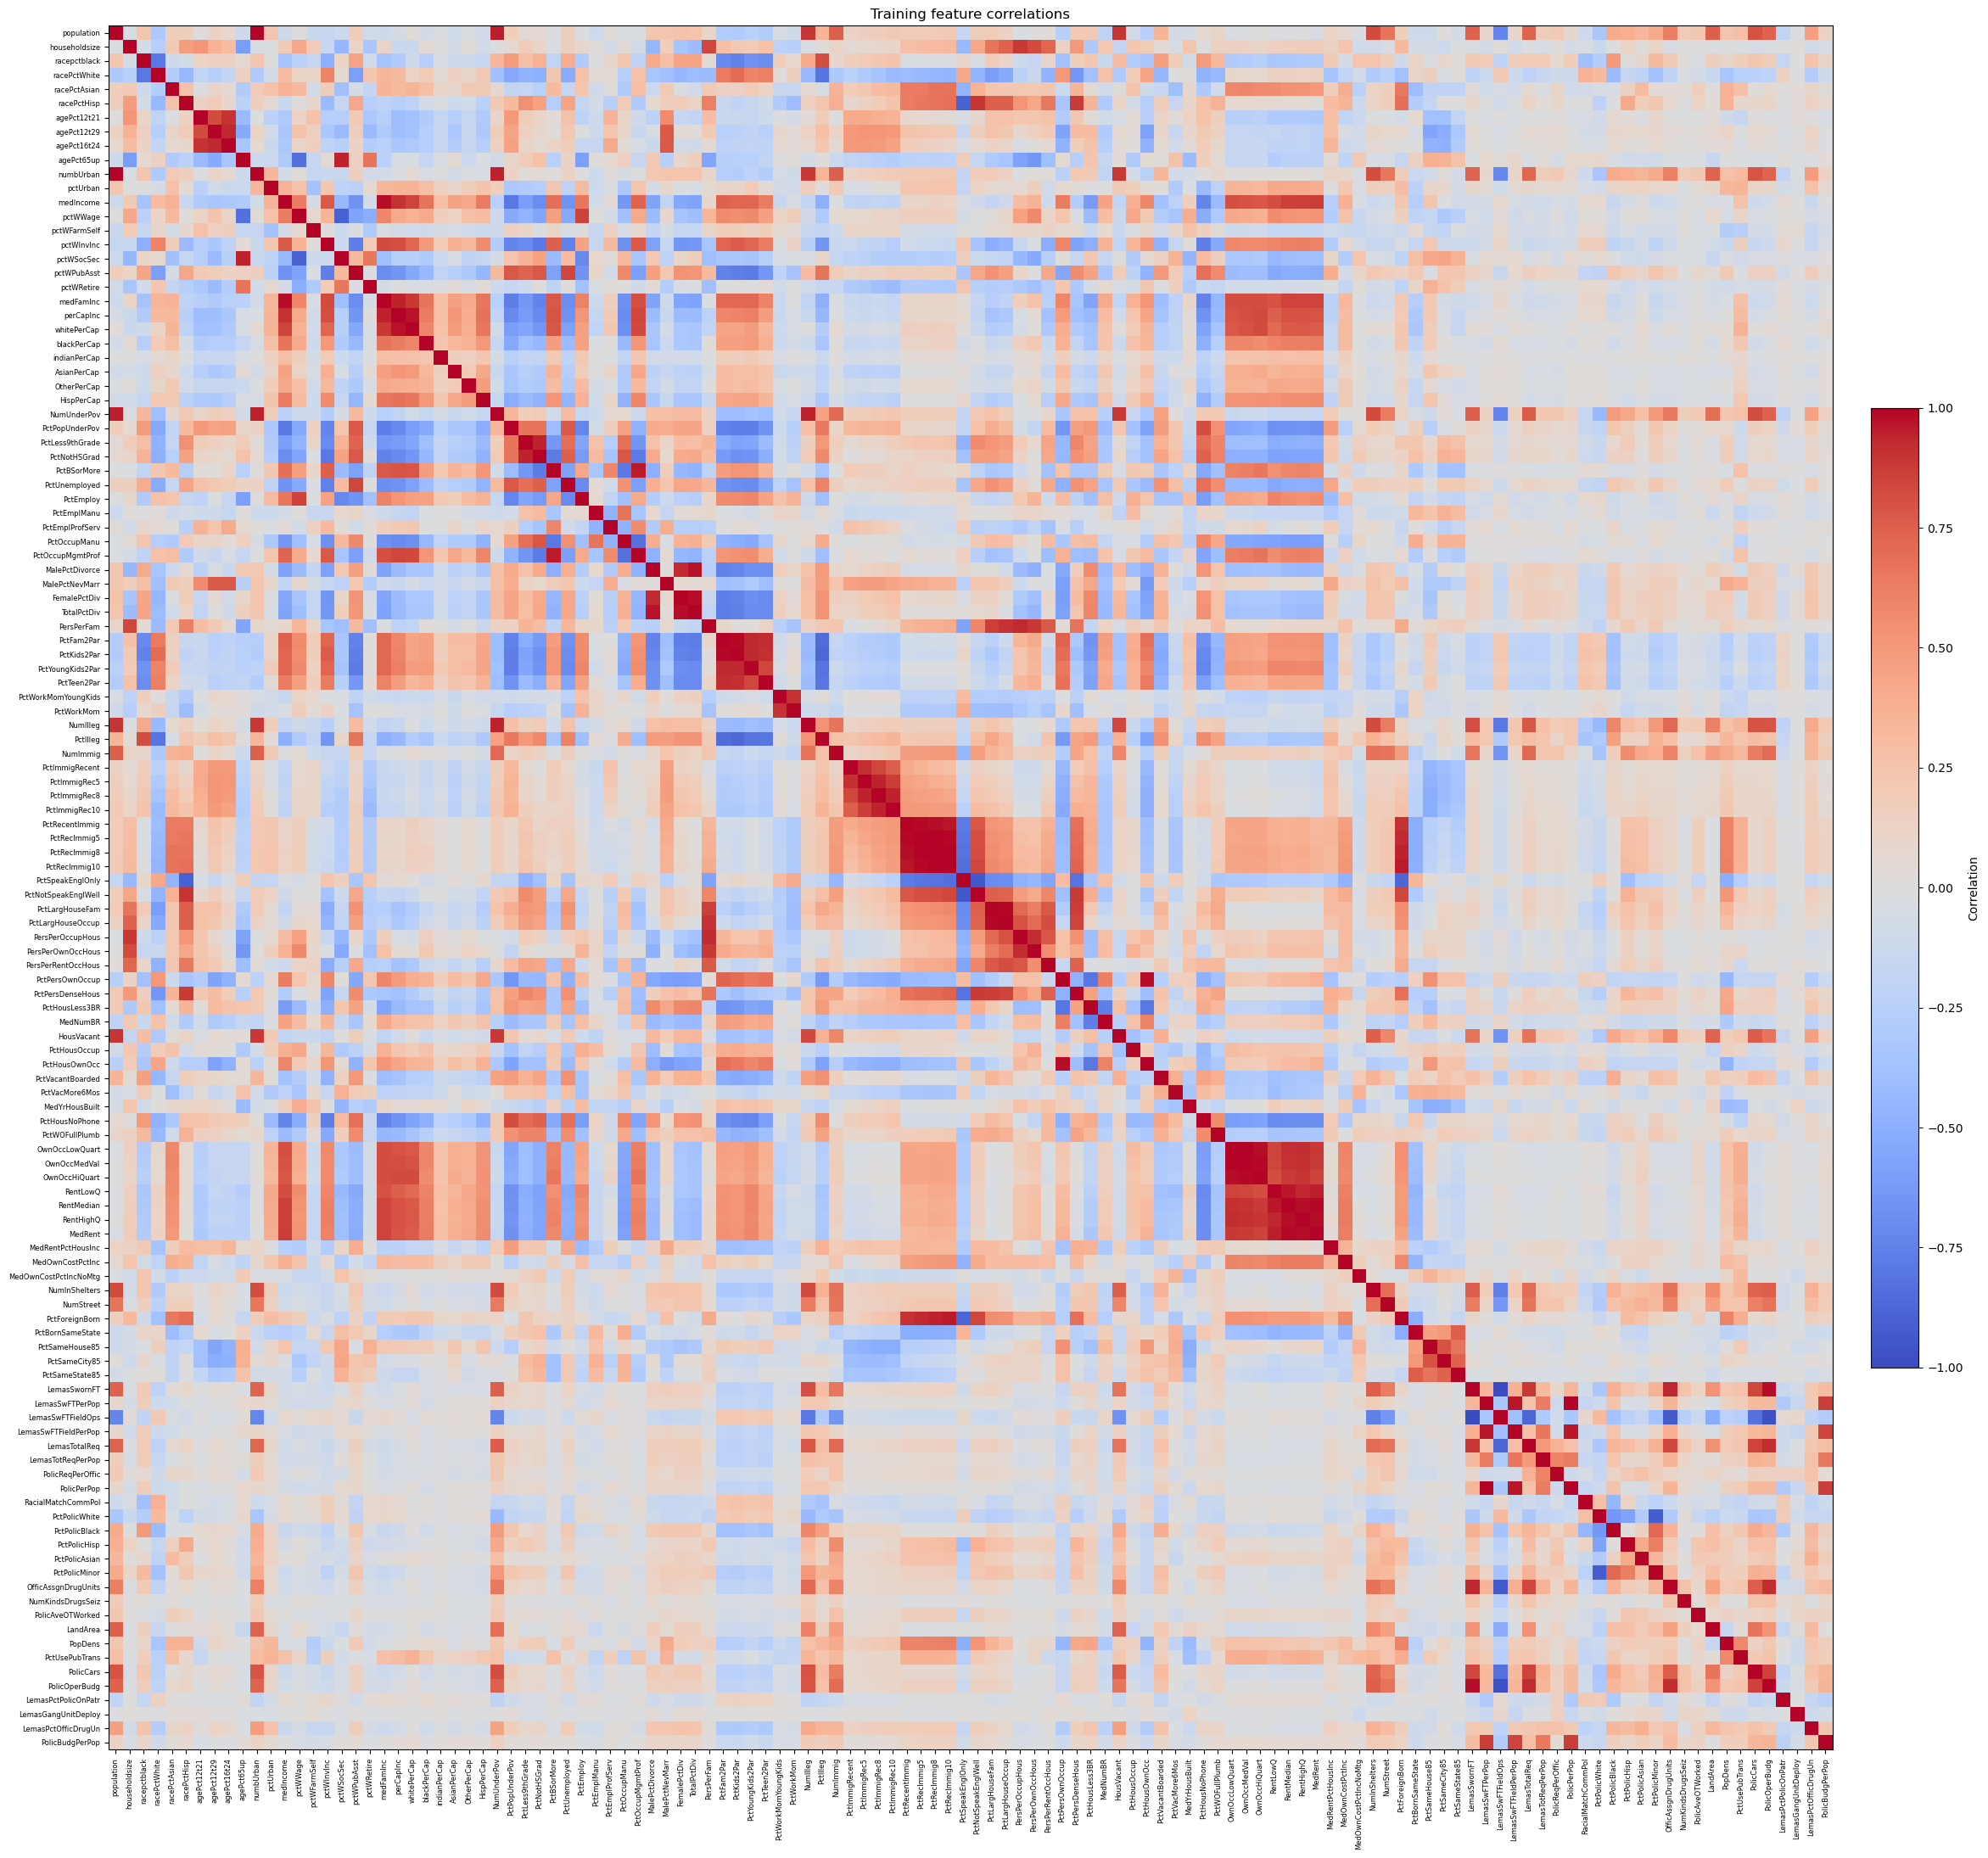

In [7]:
corr = x_plot.corr()
fig, ax = plt.subplots(figsize=(24, 22))
image = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=6)
ax.set_yticklabels(corr.columns, fontsize=6)
fig.colorbar(image, ax=ax, fraction=0.025, pad=0.02, label='Correlation')
ax.set_title('Training feature correlations')
plt.tight_layout()
plt.show()

### (d)

In [8]:
col_mean = x_plot.mean()
col_std = x_plot.std(ddof=1)
cv_values = col_std / col_mean.replace(0, np.nan)
cv_table = pd.DataFrame({'mean': col_mean, 'sample_std': col_std, 'CV': cv_values})
display(cv_table.sort_values('CV', ascending=False))

,mean,sample_std,CV
PctPolicAsian,0.016254,0.089838,5.527059
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
LemasPctOfficDrugUn,0.093304,0.238201,2.552946
NumUnderPov,0.056849,0.133167,2.342443
LemasSwornFT,0.028749,0.064629,2.248042
population,0.058167,0.130359,2.241105
numbUrban,0.064649,0.131784,2.038461


### (e)

,mean,sample_std,CV
PctPolicAsian,0.016254,0.089838,5.527059
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
LemasPctOfficDrugUn,0.093304,0.238201,2.552946
NumUnderPov,0.056849,0.133167,2.342443
LemasSwornFT,0.028749,0.064629,2.248042
population,0.058167,0.130359,2.241105
numbUrban,0.064649,0.131784,2.038461


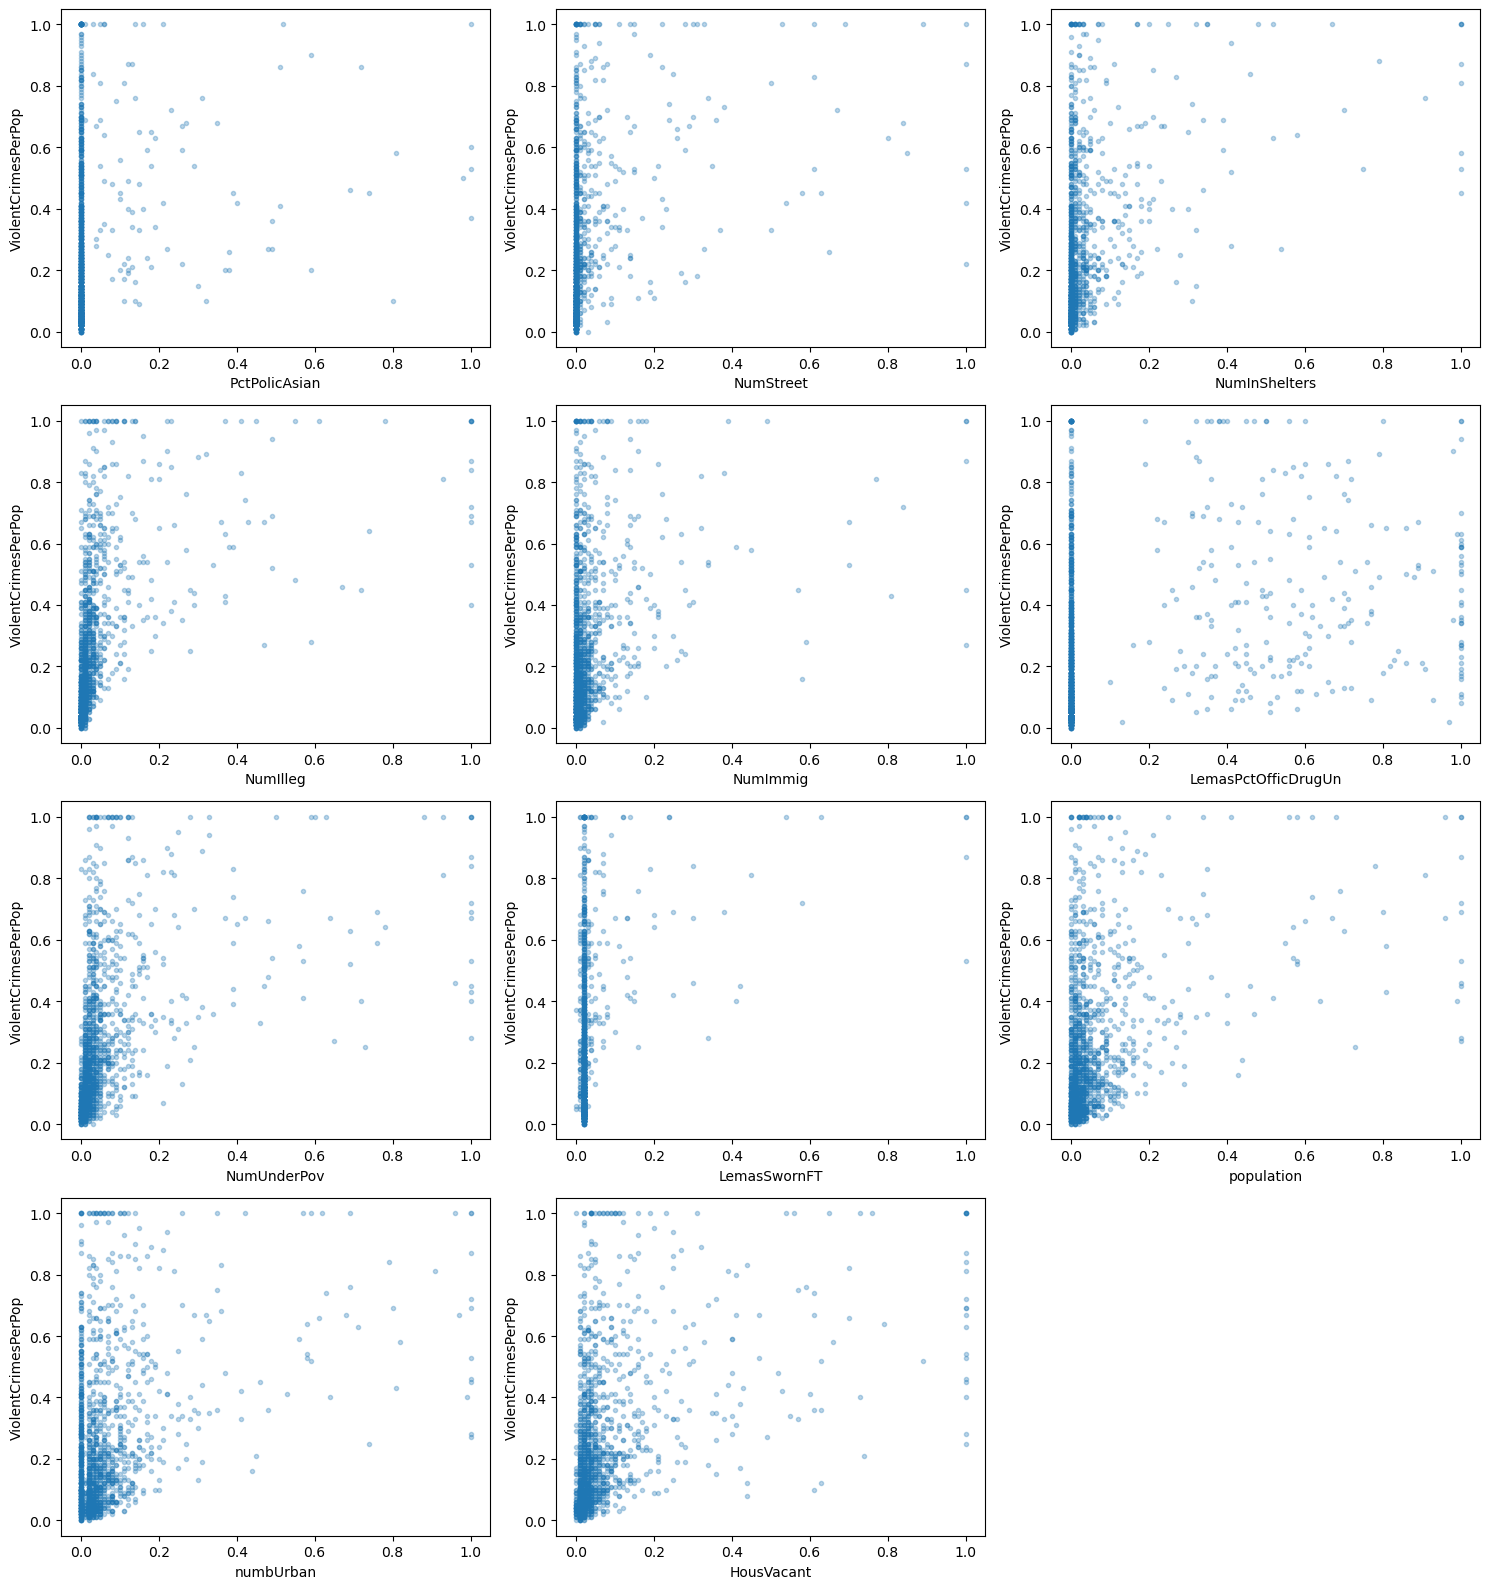

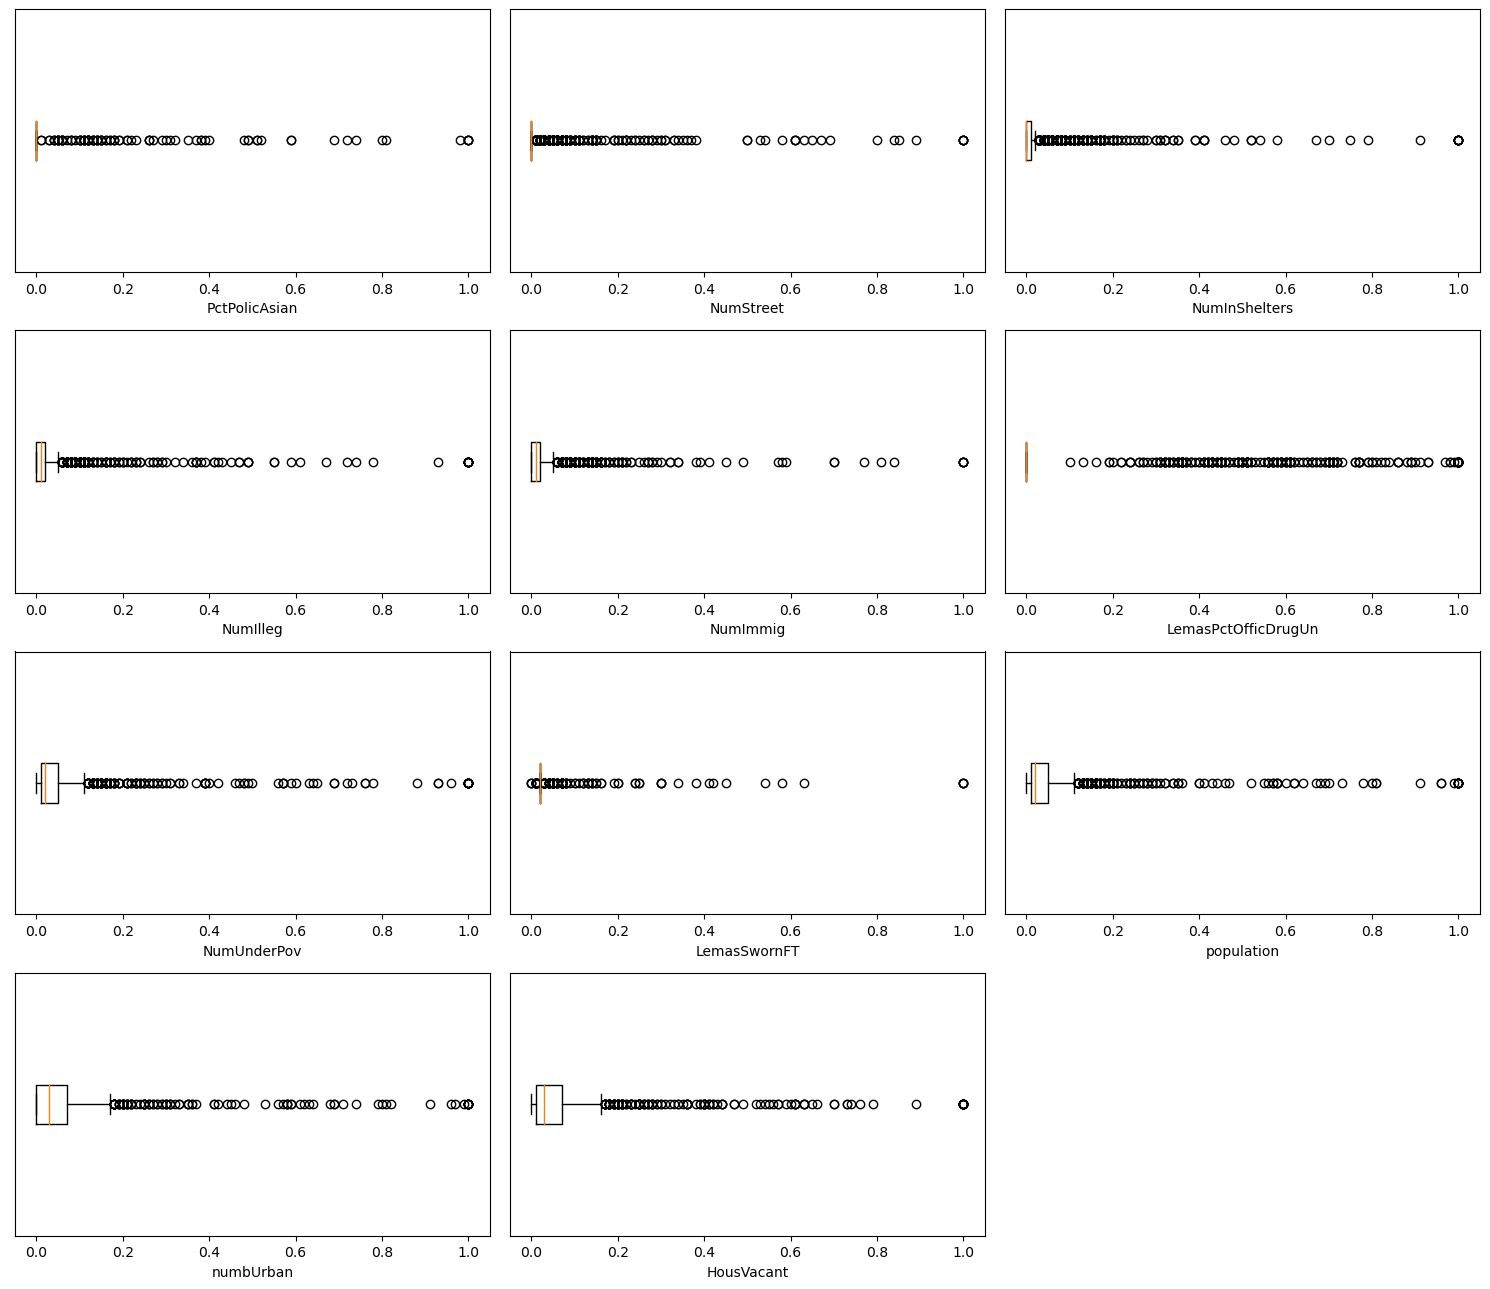

In [9]:
n_features = int(np.sqrt(128))
selected = cv_values.nlargest(n_features).index.tolist()
display(cv_table.loc[selected])
fig, axes = plt.subplots(4, 3, figsize=(15, 16))
for ax, name in zip(axes.flat, selected):
    ax.scatter(x_plot[name], y_train, s=9, alpha=0.3)
    ax.set_xlabel(name)
    ax.set_ylabel('ViolentCrimesPerPop')
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(4, 3, figsize=(15, 13))
for ax, name in zip(axes.flat, selected):
    ax.boxplot(x_plot[name], vert=False)
    ax.set_xlabel(name)
    ax.set_yticks([])
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

No. In most plots, most points are close to 0 and only a few points are large. NumIlleg and NumUnderPov show a weak upward trend, but the points are very spread out. LemasSwornFT has a vertical line of points because most of its values are missing and I filled them with the median. LemasPctOfficDrugUn also has a vertical line, but this is because many of its original values are 0. Scatter plots can suggest a relationship, but they cannot show statistical significance, so I cannot draw conclusions about these features from them.

### (f)

The fitted model is $\widehat{\mathrm{ViolentCrimesPerPop}} = b_0 + \sum_{j=1}^{122} b_j x_j$. 

In [10]:
imputer = SimpleImputer(strategy='median')
x_train_filled = imputer.fit_transform(x_train)
x_test_filled = imputer.transform(x_test)
x_train_filled = sm.add_constant(x_train_filled)
x_test_filled = sm.add_constant(x_test_filled)

linear = sm.OLS(y_train, x_train_filled).fit()
coef = pd.Series(np.asarray(linear.params), index=['Intercept'] + list(x_train.columns))
display(coef.rename('Coefficient').to_frame())

linear_pred = linear.predict(x_test_filled)
test_mse = mean_squared_error(y_test, linear_pred)
print('Test MSE:', round(test_mse, 6))

,Coefficient
Intercept,0.493745
population,-0.006899
householdsize,-0.014081
racepctblack,0.276388
racePctWhite,0.005347
racePctAsian,-0.029802
racePctHisp,0.006391
agePct12t21,0.184196
agePct12t29,-0.343314
agePct16t24,-0.131163


Test MSE: 0.017966


### (g)

$\hat y=b_0+\sum_{j=1}^{122}b_jz_j$, where $z_j$ is the standardized predictor. 

In [11]:
folds = KFold(n_splits=5, shuffle=True, random_state=1)
ridge = Pipeline([('imputer', SimpleImputer(strategy='median')),
                  ('scale', StandardScaler()),
                  ('model', Ridge())])
ridge_params = {'model__alpha': np.logspace(-4, 5, 55)}
ridge_search = GridSearchCV(ridge, ridge_params, cv=folds, scoring='neg_mean_squared_error', n_jobs=1)
ridge_search.fit(x_train, y_train)

test_mse = mean_squared_error(y_test, ridge_search.predict(x_test))
print('Selected lambda:', ridge_search.best_params_['model__alpha'])
print('Test MSE:', round(test_mse, 6))

ridge_model = ridge_search.best_estimator_.named_steps['model']
coef = pd.Series(ridge_model.coef_, index=x_train.columns)
print('Intercept:', ridge_model.intercept_)
display(coef.rename('Coefficient').to_frame())

Selected lambda: 46.41588833612773
Test MSE: 0.0175
Intercept: 0.2406086956521739


,Coefficient
population,-0.005062
householdsize,0.002270
racepctblack,0.052786
racePctWhite,-0.014747
racePctAsian,-0.007302
racePctHisp,-0.001717
agePct12t21,0.009826
agePct12t29,-0.030208
agePct16t24,-0.005114
agePct65up,0.009351


### (h)

$\hat y=b_0+\sum_jb_jx_j$ for the unstandardized model. The standardized model uses $z_j$ instead of $x_j$. Only nonzero coefficients are listed.

In [12]:
lasso = Pipeline([('imputer', SimpleImputer(strategy='median')),
                  ('model', Lasso(max_iter=100000, tol=1e-5))])
lasso_params = {'model__alpha': np.logspace(-5, 0, 51)}
lasso_search = GridSearchCV(lasso, lasso_params, cv=folds, scoring='neg_mean_squared_error', n_jobs=1)
lasso_search.fit(x_train, y_train)

test_mse = mean_squared_error(y_test, lasso_search.predict(x_test))
lasso_model = lasso_search.best_estimator_.named_steps['model']
coef = pd.Series(lasso_model.coef_, index=x_train.columns)
print('LASSO without standardization')
print('Intercept:', lasso_model.intercept_)
print('Selected lambda:', lasso_search.best_params_['model__alpha'])
print('Test MSE:', round(test_mse, 6))
print('Selected features:', (coef != 0).sum())
display(coef[coef != 0].rename('Coefficient').to_frame())

LASSO without standardization
Intercept: 0.4220760212642761
Selected lambda: 7.943282347242822e-05
Test MSE: 0.017691
Selected features: 79


,Coefficient
racepctblack,0.269808
racePctAsian,-0.019900
agePct12t21,0.084838
agePct12t29,-0.324729
agePct65up,0.008110
pctUrban,0.041823
pctWWage,-0.101560
pctWFarmSelf,0.032244
pctWInvInc,-0.129421
pctWSocSec,0.073260


In [13]:
lasso_scaled = Pipeline([('imputer', SimpleImputer(strategy='median')),
                         ('scale', StandardScaler()),
                         ('model', Lasso(max_iter=100000, tol=1e-5))])
scaled_search = GridSearchCV(lasso_scaled, lasso_params, cv=folds, scoring='neg_mean_squared_error', n_jobs=1)
scaled_search.fit(x_train, y_train)

test_mse = mean_squared_error(y_test, scaled_search.predict(x_test))
scaled_model = scaled_search.best_estimator_.named_steps['model']
coef = pd.Series(scaled_model.coef_, index=x_train.columns)
print('LASSO with standardization')
print('Intercept:', scaled_model.intercept_)
print('Selected lambda:', scaled_search.best_params_['model__alpha'])
print('Test MSE:', round(test_mse, 6))
print('Selected features:', (coef != 0).sum())
display(coef[coef != 0].rename('Coefficient').to_frame())

LASSO with standardization
Intercept: 0.2406086956521739
Selected lambda: 0.0005011872336272725
Test MSE: 0.017759
Selected features: 79


,Coefficient
population,-0.000712
racepctblack,0.068434
racePctAsian,-0.002746
agePct12t21,0.014512
agePct12t29,-0.048193
pctUrban,0.017699
pctWWage,-0.016279
pctWFarmSelf,0.005638
pctWInvInc,-0.023987
pctWSocSec,0.012259


Test MSE is 0.017691 without standardization and 0.017759 with standardization. The unstandardized model has slightly lower test error, but the difference is very small. Both models select 79 features. So standardization has little effect on the test error here.

### (i)

$\hat y=b_0+\sum_{m=1}^{M}b_m\mathrm{PC}_m$. 

In [14]:
pcr = Pipeline([('imputer', SimpleImputer(strategy='median')),
                ('scale', StandardScaler()),
                ('pca', PCA(svd_solver='full')),
                ('model', LinearRegression())])
pcr_params = {'pca__n_components': list(range(1, x_train.shape[1] + 1))}
pcr_search = GridSearchCV(pcr, pcr_params, cv=folds, scoring='neg_mean_squared_error', n_jobs=1)
pcr_search.fit(x_train, y_train)

best_m = pcr_search.best_params_['pca__n_components']
test_mse = mean_squared_error(y_test, pcr_search.predict(x_test))
print('Selected M:', best_m)
print('Test MSE:', round(test_mse, 6))

pcr_model = pcr_search.best_estimator_.named_steps['model']
pc_names = ['PC' + str(i) for i in range(1, best_m + 1)]
coef = pd.Series(pcr_model.coef_, index=pc_names)
print('Intercept:', pcr_model.intercept_)
display(coef.rename('Coefficient').to_frame())

Selected M: 96
Test MSE: 0.018325
Intercept: 0.24060869565217394


,Coefficient
PC1,0.030879
PC2,0.013020
PC3,0.006746
PC4,-0.001205
PC5,-0.016257
PC6,0.003101
PC7,0.010033
PC8,-0.032646
PC9,0.016212
PC10,-0.008693


### (j)

$\hat y(x)=0.5+0.05\sum_{t=1}^{300}f_t(x)$, where each $f_t$ is a fitted tree.

In [15]:
boost = XGBRegressor(objective='reg:squarederror', booster='gbtree', n_estimators=300, max_depth=3,
                     learning_rate=0.05, reg_lambda=0, tree_method='hist', random_state=1, n_jobs=1)
boost_model = Pipeline([('imputer', SimpleImputer(strategy='median')),
                        ('model', boost)])
boost_params = {'model__reg_alpha': [0] + list(np.logspace(-4, 2, 13))}
boost_search = GridSearchCV(boost_model, boost_params, cv=folds, scoring='neg_mean_squared_error', n_jobs=1)
boost_search.fit(x_train, y_train)

test_mse = mean_squared_error(y_test, boost_search.predict(x_test))
print('Selected alpha:', boost_search.best_params_['model__reg_alpha'])
print('Test MSE:', round(test_mse, 6))
display(boost_search.best_estimator_.named_steps['model'])

Selected alpha: 1.0
Test MSE: 0.016788


XGBRegressor(base_score=None, booster='gbtree', callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, gpu_id=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.05, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=3, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             n_estimators=300, n_jobs=1, num_parallel_tree=None, predictor=None,
             random_state=1, ...)